# Portfolio Task 3 - COVID-19 Image Classification

**Objective:** develop and compare image classifiers, progressing from traditional ML
baselines in **Part A** to convolutional neural networks in **Part B**.
The dataset contains three chest X-ray classes: Covid, Normal, and Viral Pneumonia.

**Scope:** Part A implements the ML baselines. Part B implements and compares two
CNN variants using the same cleaned test set. LSTM and Part E are excluded.

## Notebook outline

1. [Environment, CUDA check, and baseline settings](#environment-and-configuration)
2. [Part A - Traditional machine learning](#part-a)
   - A.1 Load and analyse the dataset
   - A.2 Prepare image features and scaling
   - A.3 Train Random Forest and PyTorch MLP classifiers
   - A.4 Evaluate and compare the baselines
   - A.5 Visualise and interpret the results
   - Save Part A reproducibility artifacts
3. [Part B - CNN image classification](#part-b)
   - B.1 Load and prepare image data
   - B.2 Build and configure CNN variants
   - B.3 Train and validate the CNNs
   - B.4 Evaluate CNNs and compare with Part A
   - B.5 Save trained models and training histories
4. [Method references](#method-references)

<a id="environment-and-configuration"></a>
## Environment, CUDA check, and baseline settings

This notebook uses the existing **Conda environment `venv`** with Python 3.11.
Install the project dependencies from `requirements.txt` and register its kernel:

```powershell
conda activate venv
python -m pip install -r requirements.txt
python -m ipykernel install --sys-prefix --name venv --display-name "Python (conda venv)"
```

Select **Python (conda venv)** as the notebook kernel, then run the implemented cells
from top to bottom. CUDA availability is checked with a real tensor operation.
Random Forest runs on CPU; the PyTorch MLP and CNNs use CUDA.

The configuration cell currently defines the agreed **Part A** settings: 64 x 64 grayscale
images, 300 trees, and an MLP with hidden layers (128, 64), Adam, batch size 32, and
80 epochs. These settings and the epoch budget are fixed before test evaluation.
Part B defines its own settings: 128 x 128 inputs, at most 40 epochs, and early-stopping
patience 8. Outputs are written to `artifacts/part_a/` and `artifacts/part_b/`.
To rerun only Part B, run the shared setup cell, then Part B; Part A artifacts must already exist.

In [1]:
import os

# Set this before CUDA is initialised to enable deterministic matrix multiplication.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import hashlib
import json
import random
import sys
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from PIL import Image, ImageOps
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from torch import nn

SEED = 42
IMAGE_SIZE = (64, 64)
N_FOLDS = 5
RF_TREES = 300
MLP_HIDDEN_DIMS = (128, 64)
MLP_EPOCHS = 80
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
REQUIRE_CUDA = True  # Set False explicitly to allow a CPU-only MLP run.

PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "data" / "Covid19-dataset").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the project folder containing data/Covid19-dataset.")

DATA_DIR = PROJECT_ROOT / "data" / "Covid19-dataset"
OUTPUT_DIR = PROJECT_ROOT / "artifacts" / "part_a"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
MODEL_DIR = OUTPUT_DIR / "models"
for directory in (FIGURE_DIR, TABLE_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)


seed_everything(SEED)
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if REQUIRE_CUDA and DEVICE.type != "cuda":
    raise RuntimeError(
        "CUDA is required for this run. Select the CUDA-enabled conda venv kernel, "
        "or explicitly set REQUIRE_CUDA=False to run the MLP on CPU."
    )

# A real tensor operation verifies CUDA execution, beyond checking the driver.
probe = torch.ones((4, 4), device=DEVICE)
assert torch.allclose(probe @ probe, torch.full_like(probe, 4.0))
del probe

runtime_info = {
    "python_executable": sys.executable,
    "python_version": sys.version.split()[0],
    "environment": Path(sys.prefix).name,
    "pytorch_version": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "pytorch_cuda_runtime": torch.version.cuda,
    "mlp_device": str(DEVICE),
    "gpu_name": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "random_forest_device": "cpu",
    "packages": {name: version(name) for name in (
        "numpy", "scipy", "scikit-learn", "pandas", "matplotlib", "Pillow",
        "joblib", "nbformat", "nbclient", "ipykernel",
    )},
}
display(pd.Series({key: value for key, value in runtime_info.items() if key != "packages"}, name="Runtime"))

python_executable       C:\Users\Admin\anaconda3\envs\venv\python.exe
python_version                                                3.11.15
environment                                                      venv
pytorch_version                                          2.11.0+cu128
cuda_available                                                   True
pytorch_cuda_runtime                                             12.8
mlp_device                                                     cuda:0
gpu_name                                   NVIDIA GeForce RTX 3070 Ti
random_forest_device                                              cpu
Name: Runtime, dtype: object

<a id="part-a"></a>
## Part A - Traditional Machine Learning Baselines

Compare **Random Forest** and a **PyTorch MLP Classifier** using the same flattened
grayscale image features. The MLP is a fully connected classification baseline
implemented in PyTorch for CUDA support; it is not scikit-learn's `MLPClassifier` estimator.
The workflow follows A.1-A.5 and establishes the reference results for the later CNNs.

### A.1 - Load and analyse the dataset

The target is the **categorical class folder**, so this is a three-class classification
problem. The supplied `train/` and `test/` folders already provide approximately an
80/20 split; their provenance is retained instead of reshuffling test images into training.
Every image is decoded to check readability. EXIF orientation is applied and all modes
are converted to grayscale consistently. Native grayscale pixels and dimensions form
a content hash for detecting exact duplicates before any model fitting.

In [2]:
CLASS_NAMES = sorted(path.name for path in (DATA_DIR / "train").iterdir() if path.is_dir())
test_class_names = sorted(path.name for path in (DATA_DIR / "test").iterdir() if path.is_dir())
if len(CLASS_NAMES) < 2 or CLASS_NAMES != test_class_names:
    raise ValueError("Train and test must contain the same two or more class folders.")
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}


def inspect_images(data_dir):
    records = []
    for split in ("train", "test"):
        for class_name in CLASS_NAMES:
            folder = data_dir / split / class_name
            paths = sorted(path for path in folder.rglob("*")
                           if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS)
            if not paths:
                raise ValueError(f"No images found in {folder}.")
            for path in paths:
                try:
                    with Image.open(path) as image:
                        original_mode = image.mode
                        gray = ImageOps.exif_transpose(image).convert("L")
                        gray.load()
                        fingerprint = hashlib.sha256(
                            str(gray.size).encode("ascii") + gray.tobytes()
                        ).hexdigest()
                        records.append({
                            "relative_path": path.relative_to(data_dir).as_posix(),
                            "split": split,
                            "class_name": class_name,
                            "label": CLASS_TO_INDEX[class_name],
                            "width": gray.width,
                            "height": gray.height,
                            "original_mode": original_mode,
                            "pixel_hash": fingerprint,
                        })
                except (OSError, ValueError) as error:
                    raise ValueError(f"Cannot decode image: {path}") from error
    return pd.DataFrame(records).sort_values(["split", "relative_path"]).reset_index(drop=True)


raw_manifest = inspect_images(DATA_DIR)
original_counts = pd.crosstab(raw_manifest["class_name"], raw_manifest["split"])
display(original_counts.reindex(CLASS_NAMES)[["train", "test"]])
display(raw_manifest[["width", "height"]].describe().round(1))
display(raw_manifest["original_mode"].value_counts().rename("Image count").to_frame())
print(f"Original images: {len(raw_manifest)} | Classes: {len(CLASS_NAMES)}")
print(f"Target mapping: {CLASS_TO_INDEX}")

split,train,test
class_name,,
Covid,111,26
Normal,70,20
Viral Pneumonia,70,20


,width,height
count,317.0,317.0
mean,1624.6,1352.9
std,607.0,577.9
min,416.0,341.0
25%,1216.0,891.0
50%,1582.0,1319.0
75%,1980.0,1668.0
max,4248.0,4095.0


,Image count
original_mode,
RGB,267
L,42
RGBA,8


Original images: 317 | Classes: 3
Target mapping: {'Covid': 0, 'Normal': 1, 'Viral Pneumonia': 2}


#### Duplicate audit and reproducible split

Within each split, retain the first path in sorted order for each native grayscale
pixel hash. If a hash occurs in both splits, exclude its training copy while preserving
the held-out test copy. Conflicting labels for identical images cause an error.
This audit uses image identity to prevent leakage; test outcomes never guide training.
Only manifests are filtered: **source images are not deleted or changed**.
Exact deduplication cannot establish patient-level independence because this dataset
does not supply patient identifiers.

,original_train,original_test,clean_train,clean_test
class_name,,,,
Covid,111,26,105,25
Normal,70,20,68,20
Viral Pneumonia,70,20,69,20


,relative_path,excluded_reason
20,test/Covid/auntminnie-2020_01_31_20_24_2322_20...,duplicate_within_split
113,train/Covid/069.jpg,training_image_also_in_test
139,train/Covid/COVID-00003b.jpg,training_image_also_in_test
148,train/Covid/COVID-00012.jpg,training_image_also_in_test
160,train/Covid/COVID-00022.jpg,training_image_also_in_test
171,train/Covid/COVID-00033.jpg,training_image_also_in_test
175,train/Covid/COVID-00037.jpg,training_image_also_in_test
189,train/Normal/020.jpeg,duplicate_within_split
243,train/Normal/094.jpeg,duplicate_within_split
256,train/Viral Pneumonia/020.jpeg,duplicate_within_split


Clean split: 242 train / 65 test (78.8% / 21.2%)


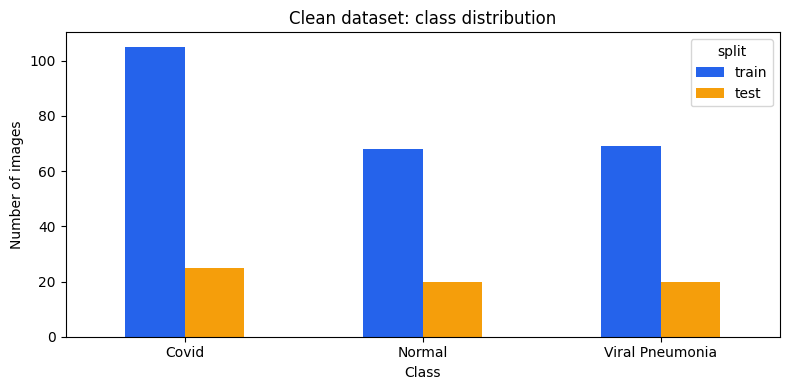

In [3]:
if raw_manifest.groupby("pixel_hash")["label"].nunique().gt(1).any():
    raise ValueError("Identical grayscale images have conflicting class labels.")

manifest = raw_manifest.copy()
manifest["excluded_reason"] = ""
within_split_duplicates = manifest.duplicated(["split", "pixel_hash"], keep="first")
manifest.loc[within_split_duplicates, "excluded_reason"] = "duplicate_within_split"
test_hashes = set(manifest.loc[manifest["split"].eq("test"), "pixel_hash"])
train_test_overlap = manifest["split"].eq("train") & manifest["pixel_hash"].isin(test_hashes)
manifest.loc[train_test_overlap, "excluded_reason"] = "training_image_also_in_test"
clean_manifest = manifest.loc[manifest["excluded_reason"].eq("")].copy()
excluded_manifest = manifest.loc[manifest["excluded_reason"].ne("")].copy()

train_manifest = clean_manifest.loc[clean_manifest["split"].eq("train")].reset_index(drop=True)
test_manifest = clean_manifest.loc[clean_manifest["split"].eq("test")].reset_index(drop=True)
assert set(train_manifest["pixel_hash"]).isdisjoint(test_manifest["pixel_hash"])
assert not clean_manifest.duplicated("pixel_hash").any()

clean_counts = pd.crosstab(clean_manifest["class_name"], clean_manifest["split"])
count_comparison = pd.DataFrame({
    "original_train": original_counts["train"],
    "original_test": original_counts["test"],
    "clean_train": clean_counts["train"],
    "clean_test": clean_counts["test"],
}).reindex(CLASS_NAMES)
display(count_comparison)
display(excluded_manifest[["relative_path", "excluded_reason"]])
train_fraction = len(train_manifest) / len(clean_manifest)
print(f"Clean split: {len(train_manifest)} train / {len(test_manifest)} test "
      f"({train_fraction:.1%} / {1 - train_fraction:.1%})")

manifest.to_csv(TABLE_DIR / "image_audit.csv", index=False)
clean_manifest.to_csv(TABLE_DIR / "clean_image_manifest.csv", index=False)
excluded_manifest.to_csv(TABLE_DIR / "excluded_duplicates.csv", index=False)
count_comparison.to_csv(TABLE_DIR / "class_distribution.csv")

fig, ax = plt.subplots(figsize=(8, 4))
clean_counts.reindex(CLASS_NAMES)[["train", "test"]].plot.bar(ax=ax, rot=0, color=["#2563eb", "#f59e0b"])
ax.set(title="Clean dataset: class distribution", xlabel="Class", ylabel="Number of images")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "class_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

### A.2 — Prepare image features and scaling

Resize each grayscale image to 64×64 with bilinear interpolation, scale pixel intensities
to [0, 1], and flatten to **4,096 features**. Both baselines receive the same feature
representation; no pretrained feature extractor or augmentation is used.
Flattening removes explicit spatial structure, which motivates the later CNN comparison.
Resizing may distort aspect ratios and images may retain source-specific visual cues.

`StandardScaler` is fitted **inside each CV fold using only that fold's training rows**.
After CV, a separate scaler is fitted on all cleaned training rows for final refitting.
The same scaled arrays are passed to both classifiers. Trees do not need scaling,
but using it keeps the input pipeline consistent; the MLP benefits from standardisation.

X_train: (242, 4096), y_train: (242,)
X_test:  (65, 4096), y_test:  (65,)
Image representation: height=64, width=64, channels=1


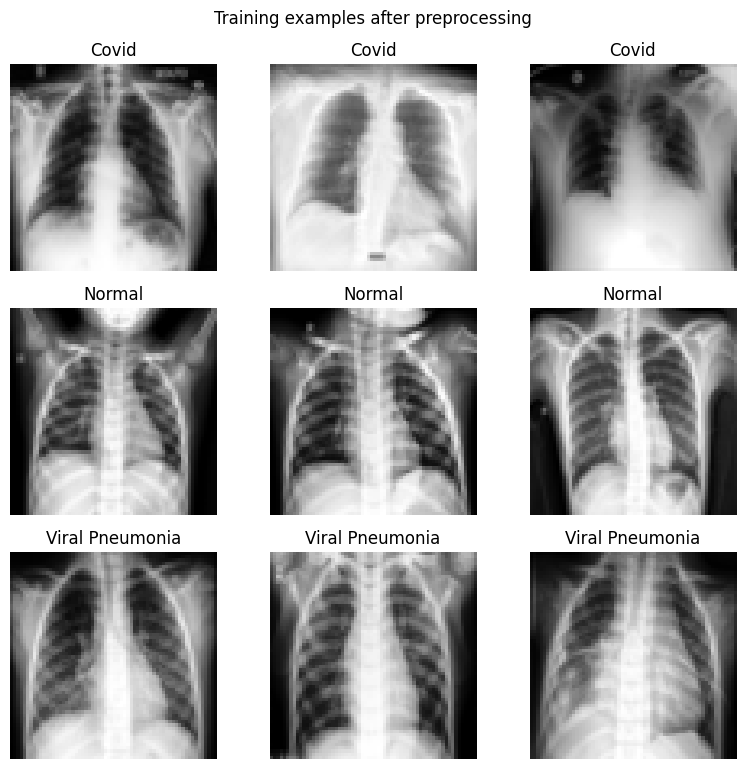

In [4]:
def load_pixel_features(image_manifest):
    features = []
    for relative_path in image_manifest["relative_path"]:
        with Image.open(DATA_DIR / relative_path) as image:
            gray = ImageOps.exif_transpose(image).convert("L")
            resized = gray.resize(IMAGE_SIZE, resample=Image.Resampling.BILINEAR)
            features.append(np.asarray(resized, dtype=np.float32).reshape(-1) / 255.0)
    return np.stack(features)


X_train = load_pixel_features(train_manifest)
X_test = load_pixel_features(test_manifest)
y_train = train_manifest["label"].to_numpy(dtype=np.int64)
y_test = test_manifest["label"].to_numpy(dtype=np.int64)

assert X_train.shape == (len(y_train), IMAGE_SIZE[0] * IMAGE_SIZE[1])
assert X_test.shape == (len(y_test), X_train.shape[1])
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_test.min() <= X_test.max() <= 1

# Guard against additional identical inputs introduced by resizing.
train_feature_hashes = [hashlib.sha256(row.tobytes()).hexdigest() for row in X_train]
test_feature_hashes = [hashlib.sha256(row.tobytes()).hexdigest() for row in X_test]
assert len(set(train_feature_hashes)) == len(train_feature_hashes), "Repeated training features: review the audit."
assert len(set(test_feature_hashes)) == len(test_feature_hashes), "Repeated test features: review the audit."
assert set(train_feature_hashes).isdisjoint(test_feature_hashes), "Resized train/test inputs overlap."

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
print(f"Image representation: height={IMAGE_SIZE[1]}, width={IMAGE_SIZE[0]}, channels=1")

fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(8, 2.6 * len(CLASS_NAMES)), squeeze=False)
for label, class_name in enumerate(CLASS_NAMES):
    sample_indices = np.flatnonzero(y_train == label)[:3]
    for column, index in enumerate(sample_indices):
        axes[label, column].imshow(X_train[index].reshape(IMAGE_SIZE[1], IMAGE_SIZE[0]), cmap="gray")
        axes[label, column].set_title(class_name)
        axes[label, column].axis("off")
fig.suptitle("Training examples after preprocessing")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "training_examples.png", dpi=180, bbox_inches="tight")
plt.show()

### A.3 — Define and train the two classifiers

**Random Forest:** 300 trees, Gini criterion, square-root feature sampling, unrestricted
depth, fixed seed, and CPU parallelism capped at four workers.

**PyTorch MLP Classifier (128, 64):** Linear → ReLU → Linear → ReLU → Linear,
with three output logits. Cross-entropy consumes logits directly; softmax is not needed
before this loss. Use Adam, learning rate 0.001, L2 weight decay 0.0001, batch size 32,
and a fixed 80-epoch budget. There are no convolutional or recurrent layers.

All five folds use identical partitions for both models. Every fold constructs fresh
models and a fresh scaler. CV runs on training images only, sequentially for the GPU
MLP. No test metrics or test images are used for selecting hyperparameters or epochs.

In [5]:
RF_NAME = "Random Forest"
MLP_NAME = "PyTorch MLP (128, 64)"
MODEL_NAMES = [RF_NAME, MLP_NAME]


def make_random_forest(seed):
    return RandomForestClassifier(
        n_estimators=RF_TREES,
        criterion="gini",
        max_features="sqrt",
        random_state=seed,
        n_jobs=min(4, os.cpu_count() or 1),
    )


class MLPClassifier(nn.Module):
    """A fully connected classifier implemented with PyTorch, not sklearn."""

    def __init__(self, input_dim, hidden_dims, num_classes):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden_dims[0]),
            nn.ReLU(),
            nn.Linear(hidden_dims[0], hidden_dims[1]),
            nn.ReLU(),
            nn.Linear(hidden_dims[1], num_classes),
        )

    def forward(self, features):
        return self.layers(features)


def train_mlp(features, labels, seed):
    seed_everything(seed)
    model = MLPClassifier(features.shape[1], MLP_HIDDEN_DIMS, len(CLASS_NAMES)).to(DEVICE)
    feature_tensor = torch.as_tensor(features, dtype=torch.float32, device=DEVICE)
    label_tensor = torch.as_tensor(labels, dtype=torch.long, device=DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    history = []
    model.train()
    for epoch in range(1, MLP_EPOCHS + 1):
        epoch_loss = torch.zeros((), device=DEVICE)
        shuffled_indices = torch.randperm(len(labels), device=DEVICE)
        for batch_indices in shuffled_indices.split(BATCH_SIZE):
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(feature_tensor[batch_indices]), label_tensor[batch_indices])
            loss.backward()
            optimizer.step()
            epoch_loss += loss.detach() * len(batch_indices)
        history.append({"epoch": epoch, "train_loss": epoch_loss.item() / len(labels)})
    assert all(parameter.device == DEVICE for parameter in model.parameters())
    return model, pd.DataFrame(history)


@torch.inference_mode()
def predict_mlp(model, features):
    model.eval()
    model_device = next(model.parameters()).device
    feature_tensor = torch.as_tensor(features, dtype=torch.float32, device=model_device)
    return model(feature_tensor).argmax(dim=1).cpu().numpy()


def classification_scores(labels, predictions):
    return {
        "accuracy": accuracy_score(labels, predictions),
        "weighted_f1": f1_score(labels, predictions, average="weighted", zero_division=0),
        "macro_f1": f1_score(labels, predictions, average="macro", zero_division=0),
    }


class_counts = np.bincount(y_train, minlength=len(CLASS_NAMES))
if class_counts.min() < N_FOLDS:
    raise ValueError("Every training class needs at least five samples for five-fold CV.")
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))
fold_assignments = train_manifest[["relative_path", "class_name", "label", "pixel_hash"]].copy()
fold_assignments["validation_fold"] = -1
cv_records = []
oof_predictions = {name: np.full(len(y_train), -1, dtype=np.int64) for name in MODEL_NAMES}

for fold_number, (fit_indices, validation_indices) in enumerate(folds, start=1):
    fold_assignments.loc[validation_indices, "validation_fold"] = fold_number
    fold_scaler = StandardScaler()
    fold_train = fold_scaler.fit_transform(X_train[fit_indices]).astype(np.float32)
    fold_validation = fold_scaler.transform(X_train[validation_indices]).astype(np.float32)
    assert int(fold_scaler.n_samples_seen_) == len(fit_indices)
    for name in MODEL_NAMES:
        start = perf_counter()
        if name == RF_NAME:
            model = make_random_forest(SEED + fold_number)
            model.fit(fold_train, y_train[fit_indices])
            predictions = model.predict(fold_validation)
        else:
            model, _ = train_mlp(fold_train, y_train[fit_indices], SEED + fold_number)
            predictions = predict_mlp(model, fold_validation)
        oof_predictions[name][validation_indices] = predictions
        cv_records.append({
            "model": name,
            "fold": fold_number,
            "fit_samples": len(fit_indices),
            "validation_samples": len(validation_indices),
            "fit_and_predict_seconds": perf_counter() - start,
            **classification_scores(y_train[validation_indices], predictions),
        })
        print(f"Fold {fold_number}/{N_FOLDS} | {name} | "
              f"Accuracy={cv_records[-1]['accuracy']:.4f} | "
              f"weighted F1={cv_records[-1]['weighted_f1']:.4f}")
        del model

cv_results = pd.DataFrame(cv_records)
assert fold_assignments["validation_fold"].between(1, N_FOLDS).all()
assert all((predictions >= 0).all() for predictions in oof_predictions.values())
cv_summary = cv_results.groupby("model").agg(
    cv_accuracy_mean=("accuracy", "mean"),
    cv_accuracy_std=("accuracy", "std"),
    cv_weighted_f1_mean=("weighted_f1", "mean"),
    cv_weighted_f1_std=("weighted_f1", "std"),
    cv_macro_f1_mean=("macro_f1", "mean"),
).reindex(MODEL_NAMES)

# Select the baseline before evaluating the held-out test set.
ranked_cv = cv_summary.sort_values(
    ["cv_accuracy_mean", "cv_weighted_f1_mean"], ascending=False, kind="stable"
)
selected_baseline = ranked_cv.index[0]
cv_results.to_csv(TABLE_DIR / "cross_validation_folds.csv", index=False)
cv_summary.to_csv(TABLE_DIR / "cross_validation_summary.csv")
fold_assignments.to_csv(TABLE_DIR / "training_fold_assignments.csv", index=False)
display(cv_results.round(4))
display(cv_summary.round(4))
print(f"Selected baseline by mean CV accuracy (weighted F1 tie-breaker): {selected_baseline}")

Fold 1/5 | Random Forest | Accuracy=0.9388 | weighted F1=0.9387
Fold 1/5 | PyTorch MLP (128, 64) | Accuracy=0.9592 | weighted F1=0.9592
Fold 2/5 | Random Forest | Accuracy=0.9388 | weighted F1=0.9381
Fold 2/5 | PyTorch MLP (128, 64) | Accuracy=0.9592 | weighted F1=0.9599
Fold 3/5 | Random Forest | Accuracy=0.9167 | weighted F1=0.9161
Fold 3/5 | PyTorch MLP (128, 64) | Accuracy=0.9792 | weighted F1=0.9793
Fold 4/5 | Random Forest | Accuracy=0.8958 | weighted F1=0.8921
Fold 4/5 | PyTorch MLP (128, 64) | Accuracy=0.9375 | weighted F1=0.9365
Fold 5/5 | Random Forest | Accuracy=0.8958 | weighted F1=0.8962
Fold 5/5 | PyTorch MLP (128, 64) | Accuracy=0.8958 | weighted F1=0.8962


,model,fold,fit_samples,validation_samples,fit_and_predict_seconds,accuracy,weighted_f1,macro_f1
0,Random Forest,1,193,49,0.3771,0.9388,0.9387,0.9285
1,"PyTorch MLP (128, 64)",1,193,49,0.9813,0.9592,0.9592,0.9524
2,Random Forest,2,193,49,0.3708,0.9388,0.9381,0.9277
3,"PyTorch MLP (128, 64)",2,193,49,0.8093,0.9592,0.9599,0.9573
4,Random Forest,3,194,48,0.3938,0.9167,0.9161,0.9096
5,"PyTorch MLP (128, 64)",3,194,48,1.0141,0.9792,0.9793,0.9804
6,Random Forest,4,194,48,0.4879,0.8958,0.8921,0.8753
7,"PyTorch MLP (128, 64)",4,194,48,1.0568,0.9375,0.9365,0.9284
8,Random Forest,5,194,48,0.3596,0.8958,0.8962,0.8905
9,"PyTorch MLP (128, 64)",5,194,48,0.8268,0.8958,0.8962,0.8905


,cv_accuracy_mean,cv_accuracy_std,cv_weighted_f1_mean,cv_weighted_f1_std,cv_macro_f1_mean
model,,,,,
Random Forest,0.9172,0.0215,0.9162,0.0222,0.9063
"PyTorch MLP (128, 64)",0.9462,0.0318,0.9462,0.0318,0.9418


Selected baseline by mean CV accuracy (weighted F1 tie-breaker): PyTorch MLP (128, 64)


#### Final refit and held-out predictions

Fit a new scaler on **all cleaned training images**, then refit each classifier on those
same training rows with the fixed settings above. Evaluate both models once on the
cleaned held-out test set. These test results describe generalisation and do not change
the CV-based model selection. Reported fit time is descriptive, not a controlled CPU/GPU
benchmark; GPU overhead can dominate on this small dataset.

In [6]:
final_scaler = StandardScaler()
X_train_scaled = final_scaler.fit_transform(X_train).astype(np.float32)
X_test_scaled = final_scaler.transform(X_test).astype(np.float32)
assert int(final_scaler.n_samples_seen_) == len(X_train)

final_models = {}
test_predictions = {}
test_records = []
for name in MODEL_NAMES:
    start = perf_counter()
    if name == RF_NAME:
        final_model = make_random_forest(SEED)
        final_model.fit(X_train_scaled, y_train)
        train_predictions = final_model.predict(X_train_scaled)
        predictions = final_model.predict(X_test_scaled)
    else:
        final_model, mlp_history = train_mlp(X_train_scaled, y_train, SEED)
        train_predictions = predict_mlp(final_model, X_train_scaled)
        predictions = predict_mlp(final_model, X_test_scaled)
    final_models[name] = final_model
    test_predictions[name] = predictions
    test_records.append({
        "model": name,
        "device": "cpu" if name == RF_NAME else str(DEVICE),
        "train_accuracy": accuracy_score(y_train, train_predictions),
        "test_accuracy": accuracy_score(y_test, predictions),
        "test_weighted_f1": f1_score(y_test, predictions, average="weighted", zero_division=0),
        "test_macro_f1": f1_score(y_test, predictions, average="macro", zero_division=0),
        "fit_and_predict_seconds": perf_counter() - start,
    })

test_results = pd.DataFrame(test_records).set_index("model")
comparison = test_results.join(cv_summary).reindex(MODEL_NAMES)
comparison["selected_by_cv"] = comparison.index == selected_baseline
comparison.to_csv(TABLE_DIR / "model_comparison.csv")
display(comparison.round(4))
print(f"Final MLP parameter device: {next(final_models[MLP_NAME].parameters()).device}")

,device,train_accuracy,test_accuracy,test_weighted_f1,test_macro_f1,fit_and_predict_seconds,cv_accuracy_mean,cv_accuracy_std,cv_weighted_f1_mean,cv_weighted_f1_std,cv_macro_f1_mean,selected_by_cv
model,,,,,,,,,,,,
Random Forest,cpu,1.0,0.8308,0.8292,0.8183,0.4966,0.9172,0.0215,0.9162,0.0222,0.9063,False
"PyTorch MLP (128, 64)",cuda:0,1.0,0.9077,0.9073,0.9062,0.9146,0.9462,0.0318,0.9462,0.0318,0.9418,True


Final MLP parameter device: cuda:0


### A.4 — Evaluate and compare

Accuracy is the required primary metric; weighted F1 accounts for class support.
Macro F1 and per-class precision/recall/F1 provide additional visibility into the mildly
imbalanced class distribution. CV standard deviations use the five fold scores (sample
standard deviation). The small test set means a single error noticeably changes accuracy.


Random Forest — held-out classification report
                 precision    recall  f1-score   support

          Covid     0.9600    0.9600    0.9600        25
         Normal     0.8125    0.6500    0.7222        20
Viral Pneumonia     0.7083    0.8500    0.7727        20

       accuracy                         0.8308        65
      macro avg     0.8269    0.8200    0.8183        65
   weighted avg     0.8372    0.8308    0.8292        65


PyTorch MLP (128, 64) — held-out classification report
                 precision    recall  f1-score   support

          Covid     0.9200    0.9200    0.9200        25
         Normal     0.9048    0.9500    0.9268        20
Viral Pneumonia     0.8947    0.8500    0.8718        20

       accuracy                         0.9077        65
      macro avg     0.9065    0.9067    0.9062        65
   weighted avg     0.9075    0.9077    0.9073        65



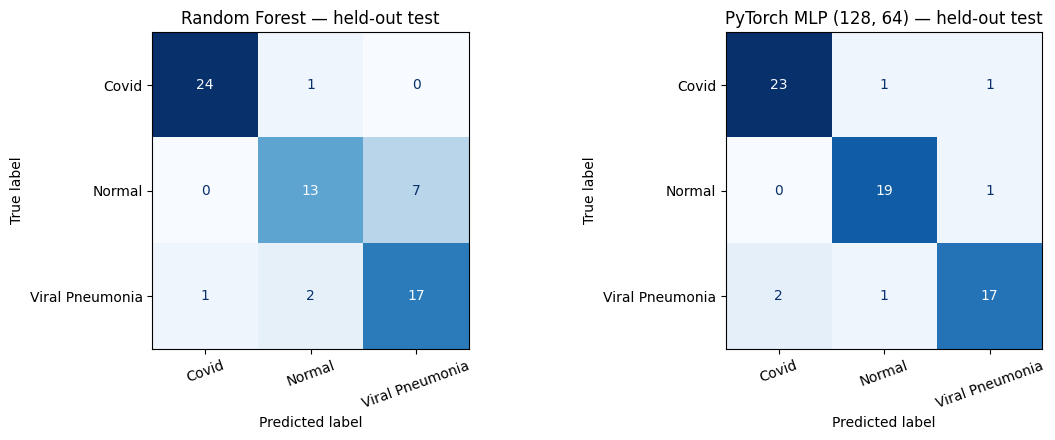

In [7]:
prediction_table = test_manifest[["relative_path", "class_name", "label"]].copy()
for name, predictions in test_predictions.items():
    print(f"\n{name} — held-out classification report")
    print(classification_report(
        y_test, predictions, labels=range(len(CLASS_NAMES)),
        target_names=CLASS_NAMES, digits=4, zero_division=0,
    ))
    report = classification_report(
        y_test, predictions, labels=range(len(CLASS_NAMES)),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0,
    )
    model_slug = "random_forest" if name == RF_NAME else "pytorch_mlp"
    pd.DataFrame(report).transpose().to_csv(TABLE_DIR / f"{model_slug}_classification_report.csv")
    prediction_table[f"{model_slug}_prediction"] = [CLASS_NAMES[index] for index in predictions]
prediction_table.to_csv(TABLE_DIR / "test_predictions.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, MODEL_NAMES):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, test_predictions[name], labels=range(len(CLASS_NAMES))),
        display_labels=CLASS_NAMES,
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name} — held-out test")
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()

### A.5 — Visualise and explain the results

The brief's A.3 explicitly specifies two ML baselines. Accordingly, this Part A figure
compares those two models. The combined chart including CNN variants belongs to the
later comparison section after the CNN experiments have been implemented.

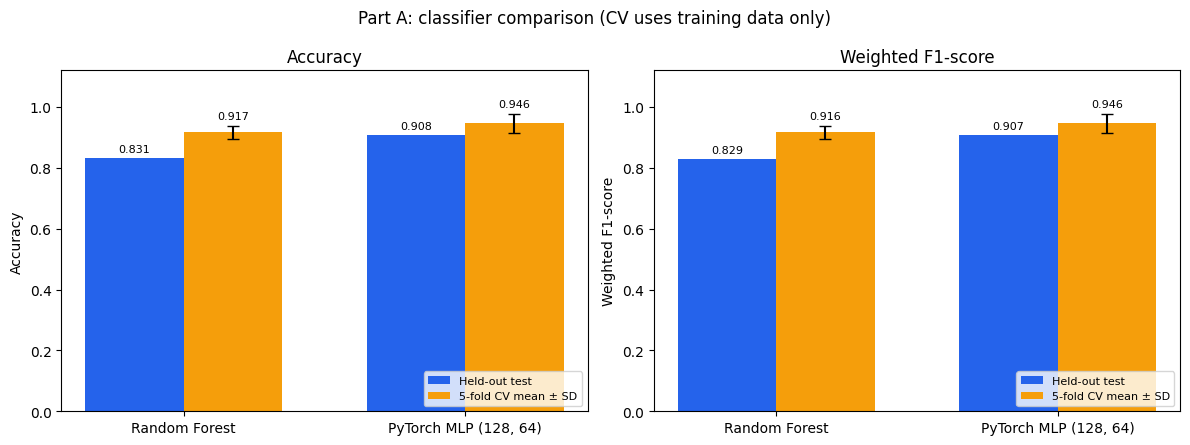

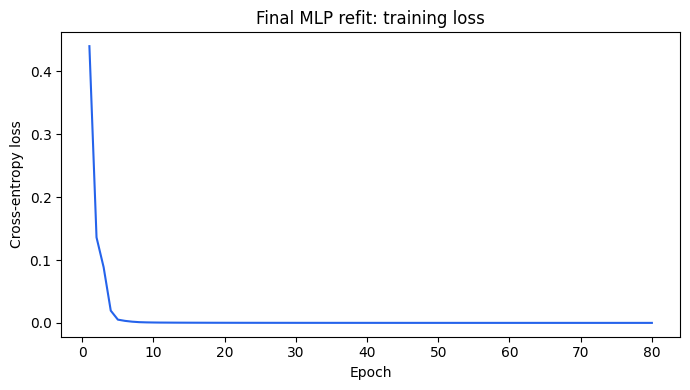

**Selected baseline: PyTorch MLP (128, 64).** Its mean five-fold CV accuracy is 0.946 ± 0.032, with mean weighted F1 0.946. The mean CV accuracy gap over Random Forest is 0.029. On the 65 unique held-out test images, its accuracy is 0.908 and weighted F1 is 0.907. One test error changes accuracy by approximately 1.54 percentage points.

A plausible explanation is that standardisation and dense layers learn useful nonlinear combinations of pixel intensities that the individual tree splits capture less efficiently. This is an interpretation, not a proven causal result. Fold variability and class-specific errors should be considered alongside the mean scores; these runs do not establish statistical significance. The test ordering may differ from CV ordering. A CNN can next be compared on the same clean image split to investigate learning spatial features.

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
positions = np.arange(len(MODEL_NAMES))
width = 0.35
for ax, metric, title in zip(
    axes, ["accuracy", "weighted_f1"], ["Accuracy", "Weighted F1-score"]
):
    test_bars = ax.bar(positions - width / 2, comparison[f"test_{metric}"], width,
                       label="Held-out test", color="#2563eb")
    cv_bars = ax.bar(positions + width / 2, comparison[f"cv_{metric}_mean"], width,
                     yerr=comparison[f"cv_{metric}_std"], capsize=4,
                     label="5-fold CV mean ± SD", color="#f59e0b")
    ax.bar_label(test_bars, fmt="%.3f", padding=3, fontsize=8)
    ax.bar_label(cv_bars, fmt="%.3f", padding=3, fontsize=8)
    ax.set(xticks=positions, xticklabels=MODEL_NAMES, ylim=(0, 1.12), ylabel=title, title=title)
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Part A: classifier comparison (CV uses training data only)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mlp_history["epoch"], mlp_history["train_loss"], color="#2563eb")
ax.set(title="Final MLP refit: training loss", xlabel="Epoch", ylabel="Cross-entropy loss")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "mlp_training_loss.png", dpi=180, bbox_inches="tight")
plt.show()

best = comparison.loc[selected_baseline]
runner_up = ranked_cv.index[1]
cv_gap = best["cv_accuracy_mean"] - comparison.loc[runner_up, "cv_accuracy_mean"]
display(Markdown(
    f"**Selected baseline: {selected_baseline}.** Its mean five-fold CV accuracy is "
    f"{best['cv_accuracy_mean']:.3f} ± {best['cv_accuracy_std']:.3f}, with mean weighted "
    f"F1 {best['cv_weighted_f1_mean']:.3f}. The mean CV accuracy gap over {runner_up} is "
    f"{cv_gap:.3f}. On the {len(y_test)} unique held-out test images, its accuracy is "
    f"{best['test_accuracy']:.3f} and weighted F1 is {best['test_weighted_f1']:.3f}. "
    f"One test error changes accuracy by approximately {100 / len(y_test):.2f} percentage points."
))
if selected_baseline == RF_NAME:
    explanation = (
        "A plausible explanation is that an ensemble of trees handles this small, high-dimensional "
        "dataset more reliably than optimising a dense network. Correlated pixel features and "
        "limited examples can make MLP generalisation difficult."
    )
else:
    explanation = (
        "A plausible explanation is that standardisation and dense layers learn useful nonlinear "
        "combinations of pixel intensities that the individual tree splits capture less efficiently."
    )
display(Markdown(
    explanation + " This is an interpretation, not a proven causal result. Fold variability and "
    "class-specific errors should be considered alongside the mean scores; these runs do not "
    "establish statistical significance. The test ordering may differ from CV ordering. "
    "A CNN can next be compared on the same clean image split to investigate learning spatial features."
))

### Save Part A reproducibility artifacts

Save the original/clean split audit, shared fold assignments, full fold scores, test
predictions, comparison tables, plots, final scaler, RF estimator, MLP state dictionary,
training loss history, settings, and runtime versions. The clean manifest can be reused
by the later CNN experiments to keep the test set consistent. Learned parameters and
local runtime paths are stored as local artifacts; no Git commit or push is performed here.

In [9]:
joblib.dump(final_scaler, MODEL_DIR / "standard_scaler.joblib")
joblib.dump(final_models[RF_NAME], MODEL_DIR / "random_forest.joblib")
torch.save({
    "state_dict": {key: value.detach().cpu() for key, value in final_models[MLP_NAME].state_dict().items()},
    "input_dim": X_train.shape[1],
    "hidden_dims": list(MLP_HIDDEN_DIMS),
    "class_names": CLASS_NAMES,
    "class_to_index": CLASS_TO_INDEX,
    "image_size": list(IMAGE_SIZE),
    "color_mode": "L",
    "resize_interpolation": "bilinear",
    "pixel_divisor": 255.0,
    "scaler_file": "standard_scaler.joblib",
}, MODEL_DIR / "pytorch_mlp.pt")
mlp_history.to_csv(TABLE_DIR / "mlp_training_history.csv", index=False)

experiment_config = {
    "seed": SEED,
    "image_size": list(IMAGE_SIZE),
    "color_mode": "L",
    "class_to_index": CLASS_TO_INDEX,
    "n_folds": N_FOLDS,
    "random_forest_trees": RF_TREES,
    "mlp_hidden_dims": list(MLP_HIDDEN_DIMS),
    "mlp_epochs": MLP_EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "original_train_samples": int(raw_manifest["split"].eq("train").sum()),
    "original_test_samples": int(raw_manifest["split"].eq("test").sum()),
    "clean_train_samples": len(y_train),
    "clean_test_samples": len(y_test),
    "selection_rule": "mean CV accuracy, then mean CV weighted F1",
    "selected_baseline": selected_baseline,
    "data_root_relative": DATA_DIR.relative_to(PROJECT_ROOT).as_posix(),
}
(OUTPUT_DIR / "experiment_config.json").write_text(json.dumps(experiment_config, indent=2), encoding="utf-8")
(OUTPUT_DIR / "runtime.json").write_text(json.dumps(runtime_info, indent=2), encoding="utf-8")
print(f"Saved tables: {TABLE_DIR}")
print(f"Saved figures: {FIGURE_DIR}")
print(f"Saved models: {MODEL_DIR}")
print("Part A complete. Continue to Part B for CNN development. Part E is excluded.")

Saved tables: d:\PortfolioTask3\artifacts\part_a\tables
Saved figures: d:\PortfolioTask3\artifacts\part_a\figures
Saved models: d:\PortfolioTask3\artifacts\part_a\models
Part A complete. Continue to Part B for CNN development. Part E is excluded.


<a id="part-b"></a>
## Part B - Deep Learning: CNN for Image Classification

Develop two CNNs from scratch, progressing from Part A's flattened-pixel baselines to
learned spatial features. Both CNNs use the same clean image manifest and held-out test
set as Part A. A stratified 20% validation subset is taken **only from training images**.
The validation set determines checkpoints, early stopping, and CNN selection; test
results do not change the configurations.

Inputs are **128 x 128 grayscale images**, scaled to [0, 1]. Each model follows the
specified Conv2D / ReLU / MaxPooling blocks, Flatten, Dense / ReLU, Dropout, and
three-class output. Training is capped at **40 epochs** with **early-stopping patience 8**.

### B.1 - Load and prepare image data

Use `ImageFolder` to read the supplied class folders, then `Subset` to retain exactly
the cleaned manifest paths. The existing 242 training images become 193 fitting and
49 validation images; the same 65 test images remain held out. Report the actual
counts below rather than assuming these numbers if the source dataset changes.
The classes are already mildly imbalanced, so no artificial imbalance is introduced.

The RTX 3070 Ti has 8 GB VRAM; the host has 20 logical CPU cores and 32 GB RAM.
Use **batch sizes 32 and 64** for the two variants and **2 workers per loader**,
pinned memory, and persistent workers. This leaves resources for the Windows desktop.
Built-in datasets and picklable transforms support Windows worker spawning in notebooks.
Training images receive online augmentation before each forward pass: horizontal flip
(probability 0.5), bilinear rotation in [-10, +10] degrees with black fill, and random
brightness/saturation factors in [0.8, 1.2]. Colour jitter runs before grayscale
conversion; saturation has little or no effect on already monochrome X-rays.
The final tensor remains 1 x 128 x 128 in [0, 1]. Source files and labels are unchanged.

Validation and test use separate, deterministic dataset instances without augmentation.
No fitted scaler is applied to CNN inputs. Seeds and the DataLoader generator control
reproducibility; each training image can receive a new transform on each epoch.

cnn_split,train,validation,test
class_name,,,
Covid,84,21,25
Normal,54,14,20
Viral Pneumonia,55,14,20


Fitting / validation / test images: 193 / 49 / 65
Class mapping: {'Covid': 0, 'Normal': 1, 'Viral Pneumonia': 2}
Training class imbalance ratio: 1.56
Device: cuda:0 | GPU: NVIDIA GeForce RTX 3070 Ti
Logical CPU cores: 20 | DataLoader workers: 2 | AMP: True


CNN input (channels, height, width): (1, 128, 128)
Training-only augmentation: {'horizontal_flip_probability': 0.5, 'rotation_degrees': 10, 'brightness_jitter': 0.2, 'saturation_jitter': 0.2, 'rotation_fill': 0, 'applied_to': 'training_only', 'mode': 'online_per_image_per_epoch'}
Training batches per epoch: [7, 4]


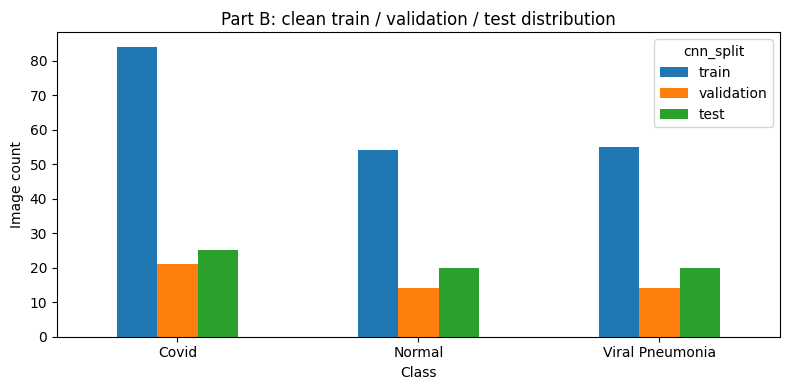

In [2]:
import shutil

import h5py
import torchvision
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode

B_IMAGE_SIZE = (128, 128)
B_INPUT_CHANNELS = 1
B_MAX_EPOCHS = 40
B_EARLY_STOPPING_PATIENCE = 8
B_AUGMENTATION_CONFIG = {
    "horizontal_flip_probability": 0.5,
    "rotation_degrees": 10,
    "brightness_jitter": 0.2,
    "saturation_jitter": 0.2,
    "rotation_fill": 0,
    "applied_to": "training_only",
    "mode": "online_per_image_per_epoch",
}
B_LR_PLATEAU_EPOCHS = 5
B_LEARNING_RATE = 1e-3
B_VALIDATION_FRACTION = 0.20
B_NUM_WORKERS = min(2, max(0, (os.cpu_count() or 1) // 4))
B_EVAL_BATCH_SIZE = 32
B_USE_AMP = DEVICE.type == "cuda"
B_VARIANTS = [
    {"id": "cnn_dense128_dropout05", "name": "CNN: Dense 128 / Dropout 0.5",
     "dense_units": 128, "dropout": 0.5, "batch_size": 32},
    {"id": "cnn_dense64_dropout03", "name": "CNN: Dense 64 / Dropout 0.3",
     "dense_units": 64, "dropout": 0.3, "batch_size": 64},
]
B_OUTPUT_DIR = PROJECT_ROOT / "artifacts" / "part_b"
B_FIGURE_DIR = B_OUTPUT_DIR / "figures"
B_TABLE_DIR = B_OUTPUT_DIR / "tables"
B_MODEL_DIR = B_OUTPUT_DIR / "models"
for directory in (B_FIGURE_DIR, B_TABLE_DIR, B_MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

part_a_dir = PROJECT_ROOT / "artifacts" / "part_a"
required_part_a_files = [
    part_a_dir / "tables" / "clean_image_manifest.csv",
    part_a_dir / "tables" / "model_comparison.csv",
    part_a_dir / "experiment_config.json",
]
if not all(file.is_file() for file in required_part_a_files):
    raise FileNotFoundError("Run Part A once to create its clean manifest and baseline results.")

part_a_config = json.loads((part_a_dir / "experiment_config.json").read_text(encoding="utf-8"))
B_CLASS_TO_INDEX = part_a_config["class_to_index"]
B_CLASS_NAMES = sorted(B_CLASS_TO_INDEX, key=B_CLASS_TO_INDEX.get)
assert list(B_CLASS_TO_INDEX.values()) == list(range(len(B_CLASS_NAMES)))
b_clean_manifest = pd.read_csv(part_a_dir / "tables" / "clean_image_manifest.csv")
b_original_train = b_clean_manifest.loc[b_clean_manifest["split"].eq("train")].reset_index(drop=True)
b_test_manifest = b_clean_manifest.loc[b_clean_manifest["split"].eq("test")].reset_index(drop=True)
assert b_clean_manifest["pixel_hash"].is_unique
assert all(b_clean_manifest["class_name"].map(B_CLASS_TO_INDEX) == b_clean_manifest["label"])

fit_indices, validation_indices = train_test_split(
    np.arange(len(b_original_train)), test_size=B_VALIDATION_FRACTION,
    random_state=SEED, stratify=b_original_train["label"],
)
b_fit_manifest = b_original_train.iloc[np.sort(fit_indices)].reset_index(drop=True)
b_validation_manifest = b_original_train.iloc[np.sort(validation_indices)].reset_index(drop=True)
b_split_manifest = pd.concat([
    b_fit_manifest.assign(cnn_split="train"),
    b_validation_manifest.assign(cnn_split="validation"),
    b_test_manifest.assign(cnn_split="test"),
], ignore_index=True)
assert b_split_manifest["pixel_hash"].is_unique
assert len(b_fit_manifest) + len(b_validation_manifest) == len(b_original_train)
b_split_manifest.to_csv(B_TABLE_DIR / "image_split_manifest.csv", index=False)

b_class_counts = pd.crosstab(b_split_manifest["class_name"], b_split_manifest["cnn_split"])
b_class_counts = b_class_counts.reindex(B_CLASS_NAMES)[["train", "validation", "test"]]
display(b_class_counts)
b_class_counts.to_csv(B_TABLE_DIR / "class_distribution.csv")
print(f"Fitting / validation / test images: {len(b_fit_manifest)} / "
      f"{len(b_validation_manifest)} / {len(b_test_manifest)}")
print(f"Class mapping: {B_CLASS_TO_INDEX}")
print(f"Training class imbalance ratio: {b_class_counts['train'].max() / b_class_counts['train'].min():.2f}")
print(f"Device: {DEVICE} | GPU: {torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'}")
print(f"Logical CPU cores: {os.cpu_count()} | DataLoader workers: {B_NUM_WORKERS} | AMP: {B_USE_AMP}")

# Random transforms operate on the RGB image before final grayscale conversion.
# Saturation has little or no effect when the source image is already monochrome.
b_train_transform = transforms.Compose([
    transforms.Lambda(ImageOps.exif_transpose),
    transforms.Resize(B_IMAGE_SIZE, interpolation=InterpolationMode.BILINEAR, antialias=True),
    transforms.RandomHorizontalFlip(p=B_AUGMENTATION_CONFIG["horizontal_flip_probability"]),
    transforms.RandomRotation(
        degrees=B_AUGMENTATION_CONFIG["rotation_degrees"],
        interpolation=InterpolationMode.BILINEAR, fill=B_AUGMENTATION_CONFIG["rotation_fill"],
    ),
    transforms.ColorJitter(
        brightness=B_AUGMENTATION_CONFIG["brightness_jitter"],
        saturation=B_AUGMENTATION_CONFIG["saturation_jitter"],
    ),
    transforms.Grayscale(num_output_channels=B_INPUT_CHANNELS),
    transforms.ToTensor(),
])
# Preserve the existing deterministic preprocessing for validation and test images.
b_eval_transform = transforms.Compose([
    transforms.Lambda(ImageOps.exif_transpose),
    transforms.Grayscale(num_output_channels=B_INPUT_CHANNELS),
    transforms.Resize(B_IMAGE_SIZE, interpolation=InterpolationMode.BILINEAR, antialias=True),
    transforms.ToTensor(),
])
b_train_folder = datasets.ImageFolder(DATA_DIR / "train", transform=b_train_transform)
b_validation_folder = datasets.ImageFolder(DATA_DIR / "train", transform=b_eval_transform)
b_test_folder = datasets.ImageFolder(DATA_DIR / "test", transform=b_eval_transform)
assert (b_train_folder.class_to_idx == b_validation_folder.class_to_idx
        == b_test_folder.class_to_idx == B_CLASS_TO_INDEX)


def subset_from_manifest(folder_dataset, image_manifest):
    path_to_index = {Path(path).resolve(): index for index, (path, _) in enumerate(folder_dataset.samples)}
    indices = [path_to_index[(DATA_DIR / path).resolve()] for path in image_manifest["relative_path"]]
    np.testing.assert_array_equal(
        np.asarray(folder_dataset.targets)[indices], image_manifest["label"].to_numpy()
    )
    return Subset(folder_dataset, indices)


b_train_dataset = subset_from_manifest(b_train_folder, b_fit_manifest)
b_validation_dataset = subset_from_manifest(b_validation_folder, b_validation_manifest)
b_test_dataset = subset_from_manifest(b_test_folder, b_test_manifest)


def make_cnn_loader(dataset, batch_size, shuffle=False, seed=SEED):
    options = {
        "batch_size": batch_size,
        "shuffle": shuffle,
        "num_workers": B_NUM_WORKERS,
        "pin_memory": DEVICE.type == "cuda",
        "persistent_workers": B_NUM_WORKERS > 0,
        "generator": torch.Generator().manual_seed(seed),
    }
    if B_NUM_WORKERS > 0:
        options["prefetch_factor"] = 2
    return DataLoader(dataset, **options)


sample_image, sample_label = b_train_dataset[0]
assert sample_image.shape == (B_INPUT_CHANNELS, *B_IMAGE_SIZE)
assert sample_image.dtype == torch.float32 and 0 <= sample_image.min() <= sample_image.max() <= 1
print(f"CNN input (channels, height, width): {tuple(sample_image.shape)}")
print(f"Training-only augmentation: {B_AUGMENTATION_CONFIG}")
print(f"Training batches per epoch: {[int(np.ceil(len(b_train_dataset) / v['batch_size'])) for v in B_VARIANTS]}")

fig, ax = plt.subplots(figsize=(8, 4))
b_class_counts.plot.bar(ax=ax, rot=0)
ax.set(title="Part B: clean train / validation / test distribution", xlabel="Class", ylabel="Image count")
fig.tight_layout()
fig.savefig(B_FIGURE_DIR / "class_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

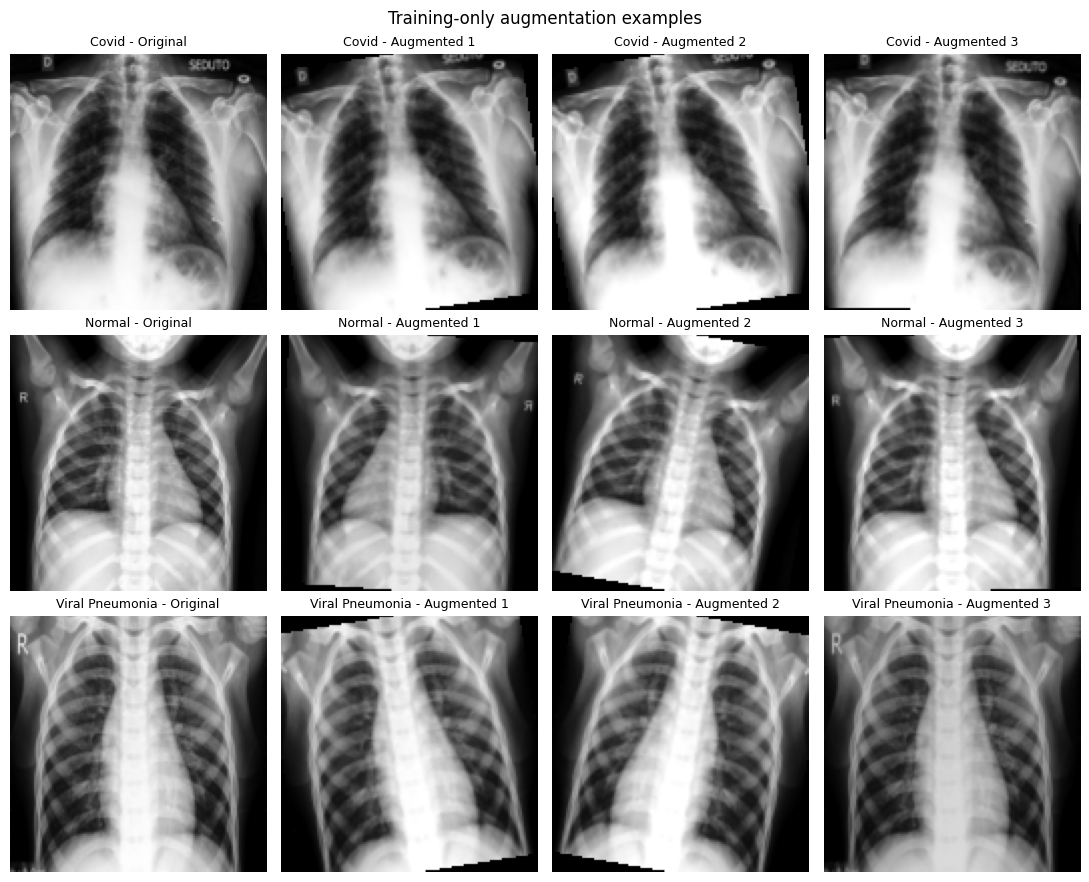

In [3]:
# Check that evaluation is repeatable and training augmentation changes the input.
torch.testing.assert_close(b_validation_dataset[0][0], b_validation_dataset[0][0], rtol=0, atol=0)
torch.testing.assert_close(b_test_dataset[0][0], b_test_dataset[0][0], rtol=0, atol=0)
assert b_train_dataset.dataset is not b_validation_dataset.dataset

fig, axes = plt.subplots(len(B_CLASS_NAMES), 4, figsize=(11, 3 * len(B_CLASS_NAMES)), squeeze=False)
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(SEED)
    for row, class_name in enumerate(B_CLASS_NAMES):
        relative_path = b_fit_manifest.loc[b_fit_manifest["class_name"].eq(class_name), "relative_path"].iloc[0]
        source_image = b_train_folder.loader(str(DATA_DIR / relative_path))
        original = b_eval_transform(source_image)
        augmented = [b_train_transform(source_image) for _ in range(3)]
        assert any(not torch.equal(original, image) for image in augmented)
        for column, image in enumerate([original, *augmented]):
            assert image.shape == (1, 128, 128) and 0 <= image.min() <= image.max() <= 1
            axes[row, column].imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
            axes[row, column].set_title(f"{class_name} - " + ("Original" if column == 0 else f"Augmented {column}"), fontsize=9)
            axes[row, column].axis("off")
fig.suptitle("Training-only augmentation examples")
fig.tight_layout()
fig.savefig(B_FIGURE_DIR / "training_augmentation_examples.png", dpi=180, bbox_inches="tight")
plt.show()

### B.2 - Build and configure CNN variants

Both architectures follow the brief, including its recommended third convolutional block:

`1 x 128 x 128 -> Conv(32, 3x3) -> ReLU -> MaxPool(2x2) -> Conv(64, 3x3) -> ReLU
-> MaxPool(2x2) -> Conv(128, 3x3) -> ReLU -> MaxPool(2x2) -> Flatten -> Dense
-> ReLU -> Dropout -> 3 logits`.

Convolutions use valid padding, giving a final spatial shape of **128 x 14 x 14** and
25,088 flattened features. CNN 1 uses Dense 128, Dropout 0.5, batch 32; CNN 2 uses
Dense 64, Dropout 0.3, batch 64. Multiple settings change together, so differences
cannot be attributed to Dense size or Dropout alone.

Use Adam and `CrossEntropyLoss`. PyTorch's cross-entropy takes raw logits; apply
**Softmax at inference** to obtain the class probabilities requested by the brief.
Print each layer's output shape and parameter count below.

In [4]:
class ImageCNN(nn.Module):
    """Three convolutional blocks and the assignment's Flatten/Dense/Dropout head."""

    def __init__(self, num_classes, dense_units, dropout, image_size=(128, 128)):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3), nn.ReLU(), nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(), nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(64, 128, kernel_size=3), nn.ReLU(), nn.MaxPool2d(kernel_size=2),
        )
        self.flatten = nn.Flatten()
        with torch.no_grad():
            flattened_features = self.features(torch.zeros(1, 1, *image_size)).numel()
        self.classifier = nn.Sequential(
            nn.Linear(flattened_features, dense_units), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(dense_units, num_classes),
        )

    def forward(self, images):
        return self.classifier(self.flatten(self.features(images)))

    def predict_proba(self, images):
        return torch.softmax(self(images), dim=1)


def make_cnn(config):
    return ImageCNN(len(B_CLASS_NAMES), config["dense_units"], config["dropout"], B_IMAGE_SIZE)


@torch.inference_mode()
def cnn_layer_summary(model):
    model.eval()
    features = torch.zeros(1, 1, *B_IMAGE_SIZE)
    rows = []
    layers = [(f"features.{name}", layer) for name, layer in model.features.named_children()]
    layers += [("flatten", model.flatten)]
    layers += [(f"classifier.{name}", layer) for name, layer in model.classifier.named_children()]
    for name, layer in layers:
        features = layer(features)
        rows.append({"layer": name, "type": layer.__class__.__name__,
                     "output_shape": str(tuple(features.shape)),
                     "parameters": sum(parameter.numel() for parameter in layer.parameters())})
    return pd.DataFrame(rows)


for variant in B_VARIANTS:
    seed_everything(SEED)
    preview_model = make_cnn(variant)
    summary = cnn_layer_summary(preview_model)
    print(variant["name"])
    print(preview_model)
    print(f"Trainable parameters: {sum(p.numel() for p in preview_model.parameters() if p.requires_grad):,}")
    display(summary)
    summary.to_csv(B_TABLE_DIR / f"{variant['id']}_architecture.csv", index=False)
    del preview_model
display(pd.DataFrame(B_VARIANTS))

CNN: Dense 128 / Dropout 0.5
ImageCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=25088, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=128, out_features=3, bias=True)
  )
)
Trainable parameters: 3,304,451


,layer,type,output_shape,parameters
0,features.0,Conv2d,"(1, 32, 126, 126)",320
1,features.1,ReLU,"(1, 32, 126, 126)",0
2,features.2,MaxPool2d,"(1, 32, 63, 63)",0
3,features.3,Conv2d,"(1, 64, 61, 61)",18496
4,features.4,ReLU,"(1, 64, 61, 61)",0
5,features.5,MaxPool2d,"(1, 64, 30, 30)",0
6,features.6,Conv2d,"(1, 128, 28, 28)",73856
7,features.7,ReLU,"(1, 128, 28, 28)",0
8,features.8,MaxPool2d,"(1, 128, 14, 14)",0
9,flatten,Flatten,"(1, 25088)",0


CNN: Dense 64 / Dropout 0.3
ImageCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=25088, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=3, bias=True)
  )
)
Trainable parameters: 1,698,563


,layer,type,output_shape,parameters
0,features.0,Conv2d,"(1, 32, 126, 126)",320
1,features.1,ReLU,"(1, 32, 126, 126)",0
2,features.2,MaxPool2d,"(1, 32, 63, 63)",0
3,features.3,Conv2d,"(1, 64, 61, 61)",18496
4,features.4,ReLU,"(1, 64, 61, 61)",0
5,features.5,MaxPool2d,"(1, 64, 30, 30)",0
6,features.6,Conv2d,"(1, 128, 28, 28)",73856
7,features.7,ReLU,"(1, 128, 28, 28)",0
8,features.8,MaxPool2d,"(1, 128, 14, 14)",0
9,flatten,Flatten,"(1, 25088)",0


,id,name,dense_units,dropout,batch_size
0,cnn_dense128_dropout05,CNN: Dense 128 / Dropout 0.5,128,0.5,32
1,cnn_dense64_dropout03,CNN: Dense 64 / Dropout 0.3,64,0.3,64


### B.3 - Train and validate the CNNs

Train each fresh model for at most **40 epochs**. Early stopping monitors validation
accuracy and stops after **8 consecutive epochs without a strict accuracy improvement**.
On equal accuracy, lower validation loss may update the saved checkpoint but does not
reset the patience counter. Restore that best checkpoint after training.

Halve the learning rate after 5 consecutive validation-loss plateaus. The PyTorch
scheduler uses `patience=4` because it reduces after the bad-epoch counter exceeds
its patience; this corresponds to 5 plateau epochs. This scheduler setting is separate
from the early-stopping patience of 8.

Use CUDA mixed precision with gradient scaling. Record loss, accuracy, learning rate,
epoch time, and peak allocated GPU memory. Both variants use the same fitting and
validation rows and initial seed. Test images are not loaded by the training routine.
Select the CNN by best validation accuracy, with validation loss as the tie-breaker.

Training metrics are measured on augmented images with Dropout active, while validation
uses unaugmented images in evaluation mode. Validation accuracy can therefore exceed
training accuracy without data leakage.

In [5]:
def run_cnn_epoch(model, loader, optimizer=None, gradient_scaler=None):
    is_training = optimizer is not None
    model.train(is_training)
    total_loss, correct, sample_count = 0.0, 0, 0
    criterion = nn.CrossEntropyLoss()
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if is_training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(is_training):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=B_USE_AMP):
                logits = model(images)
                loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite CNN loss; inspect inputs and learning rate.")
            if is_training:
                gradient_scaler.scale(loss).backward()
                gradient_scaler.step(optimizer)
                gradient_scaler.update()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        sample_count += labels.size(0)
    if sample_count == 0:
        raise ValueError("The CNN loader is empty.")
    return {"loss": total_loss / sample_count, "accuracy": correct / sample_count}


def train_cnn_variant(config):
    seed_everything(SEED)
    model = make_cnn(config).to(DEVICE)
    assert next(model.parameters()).device == DEVICE
    train_loader = make_cnn_loader(b_train_dataset, config["batch_size"], shuffle=True)
    validation_loader = make_cnn_loader(b_validation_dataset, B_EVAL_BATCH_SIZE)
    optimizer = torch.optim.Adam(model.parameters(), lr=B_LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=B_LR_PLATEAU_EPOCHS - 1,
        threshold=0.0, threshold_mode="abs",
    )
    gradient_scaler = torch.amp.GradScaler("cuda", enabled=B_USE_AMP)
    best_accuracy, best_loss, best_epoch = -float("inf"), float("inf"), 0
    best_state, accuracy_wait = None, 0
    history = []
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats(DEVICE)
        torch.cuda.synchronize(DEVICE)
    start = perf_counter()
    for epoch in range(1, B_MAX_EPOCHS + 1):
        epoch_start = perf_counter()
        learning_rate = optimizer.param_groups[0]["lr"]
        train_metrics = run_cnn_epoch(model, train_loader, optimizer, gradient_scaler)
        validation_metrics = run_cnn_epoch(model, validation_loader)
        accuracy_improved = validation_metrics["accuracy"] > best_accuracy
        checkpoint_improved = accuracy_improved or (
            validation_metrics["accuracy"] == best_accuracy and validation_metrics["loss"] < best_loss
        )
        accuracy_wait = 0 if accuracy_improved else accuracy_wait + 1
        if checkpoint_improved:
            best_accuracy, best_loss = validation_metrics["accuracy"], validation_metrics["loss"]
            best_epoch = epoch
            best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        scheduler.step(validation_metrics["loss"])
        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"], "train_accuracy": train_metrics["accuracy"],
            "val_loss": validation_metrics["loss"], "val_accuracy": validation_metrics["accuracy"],
            "learning_rate": learning_rate, "next_learning_rate": optimizer.param_groups[0]["lr"],
            "epochs_without_accuracy_improvement": accuracy_wait,
            "epoch_seconds": perf_counter() - epoch_start,
        })
        pd.DataFrame(history).to_csv(B_TABLE_DIR / f"{config['id']}_history.csv", index=False)
        print(f"{config['id']} | epoch {epoch:02d}/{B_MAX_EPOCHS} | "
              f"train loss/acc {train_metrics['loss']:.4f}/{train_metrics['accuracy']:.4f} | "
              f"val loss/acc {validation_metrics['loss']:.4f}/{validation_metrics['accuracy']:.4f} | "
              f"wait {accuracy_wait}/{B_EARLY_STOPPING_PATIENCE}", flush=True)
        if accuracy_wait >= B_EARLY_STOPPING_PATIENCE:
            print(f"Early stopping: restoring epoch {best_epoch}.", flush=True)
            break
    assert best_state is not None
    model.load_state_dict(best_state)
    restored_metrics = run_cnn_epoch(model, validation_loader)
    assert restored_metrics["accuracy"] == best_accuracy
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
    result = {
        "config": dict(config), "state_dict": best_state, "history": pd.DataFrame(history),
        "best_epoch": best_epoch, "epochs_run": len(history),
        "best_val_accuracy": best_accuracy, "best_val_loss": best_loss,
        "early_stopped": accuracy_wait >= B_EARLY_STOPPING_PATIENCE,
        "training_seconds": perf_counter() - start,
        "peak_allocated_gpu_mib": torch.cuda.max_memory_allocated(DEVICE) / 2**20 if DEVICE.type == "cuda" else 0,
    }
    del model, optimizer, train_loader, validation_loader
    return result


b_runs = {variant["id"]: train_cnn_variant(variant) for variant in B_VARIANTS}
b_training_summary = pd.DataFrame([
    {"model_id": model_id, "model": run["config"]["name"],
     "batch_size": run["config"]["batch_size"],
     **{key: run[key] for key in ("epochs_run", "best_epoch", "best_val_accuracy", "best_val_loss",
                                  "early_stopped", "training_seconds", "peak_allocated_gpu_mib")}}
    for model_id, run in b_runs.items()
]).set_index("model_id")
b_ranked_validation = b_training_summary.sort_values(
    ["best_val_accuracy", "best_val_loss"], ascending=[False, True], kind="stable"
)
B_SELECTED_ID = b_ranked_validation.index[0]
b_training_summary.to_csv(B_TABLE_DIR / "training_summary.csv")
display(b_training_summary.round(4))
print(f"CNN selected using validation only: {B_SELECTED_ID}")

cnn_dense128_dropout05 | epoch 01/40 | train loss/acc 1.0768/0.4352 | val loss/acc 0.9579/0.5102 | wait 0/8


cnn_dense128_dropout05 | epoch 02/40 | train loss/acc 0.7447/0.6891 | val loss/acc 0.4458/0.8980 | wait 0/8


cnn_dense128_dropout05 | epoch 03/40 | train loss/acc 0.4415/0.8394 | val loss/acc 0.4551/0.8367 | wait 1/8


cnn_dense128_dropout05 | epoch 04/40 | train loss/acc 0.4058/0.8497 | val loss/acc 0.4282/0.9388 | wait 0/8


cnn_dense128_dropout05 | epoch 05/40 | train loss/acc 0.3514/0.8497 | val loss/acc 0.4099/0.8571 | wait 1/8


cnn_dense128_dropout05 | epoch 06/40 | train loss/acc 0.4003/0.8497 | val loss/acc 0.3541/0.8980 | wait 2/8


... (34 outputs left out)

cnn_dense64_dropout03 | epoch 28/40 | train loss/acc 0.2815/0.8964 | val loss/acc 0.3382/0.9184 | wait 8/8


Early stopping: restoring epoch 21.


,model,batch_size,epochs_run,best_epoch,best_val_accuracy,best_val_loss,early_stopped,training_seconds,peak_allocated_gpu_mib
model_id,,,,,,,,,
cnn_dense128_dropout05,CNN: Dense 128 / Dropout 0.5,32,12,12,0.9388,0.3250,True,45.8478,244.5073
cnn_dense64_dropout03,CNN: Dense 64 / Dropout 0.3,64,28,21,0.9388,0.3375,True,125.9203,344.1973


CNN selected using validation only: cnn_dense128_dropout05


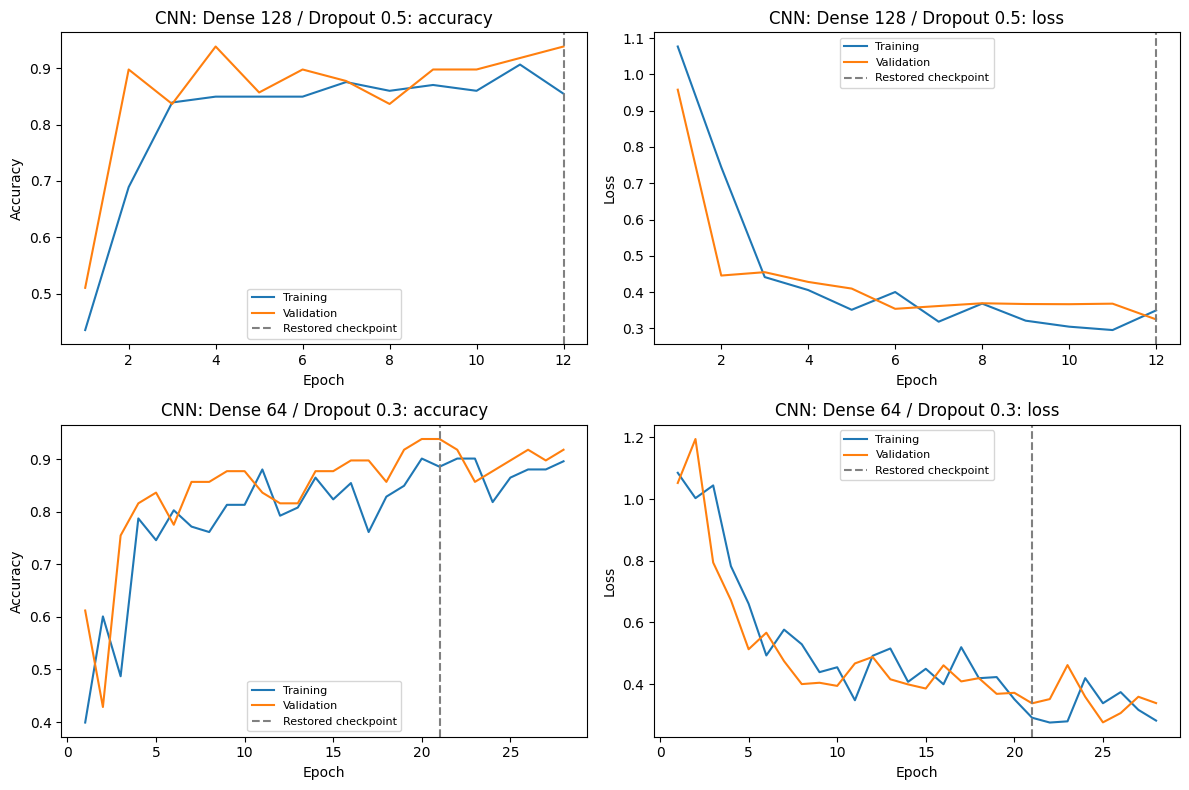

In [6]:
fig, axes = plt.subplots(len(B_VARIANTS), 2, figsize=(12, 4 * len(B_VARIANTS)), squeeze=False)
for row, variant in enumerate(B_VARIANTS):
    run = b_runs[variant["id"]]
    history = run["history"]
    for column, metric in enumerate(("accuracy", "loss")):
        ax = axes[row, column]
        ax.plot(history["epoch"], history[f"train_{metric}"], label="Training")
        ax.plot(history["epoch"], history[f"val_{metric}"], label="Validation")
        ax.axvline(run["best_epoch"], linestyle="--", color="gray", label="Restored checkpoint")
        ax.set(title=f"{variant['name']}: {metric}", xlabel="Epoch", ylabel=metric.title())
        ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(B_FIGURE_DIR / "training_validation_curves.png", dpi=180, bbox_inches="tight")
plt.show()

### B.4 - Evaluate CNNs and compare with Part A

After fixing the validation-selected checkpoints, report held-out test loss, accuracy,
weighted/macro F1, per-class precision/recall/F1, confusion matrices, and sample predictions.
Use full-precision inference and Softmax probabilities. Test loaders do not shuffle, so
saved predictions match manifest order.

All four models share the same 65 test images. Part A fitted its final models on all
242 cleaned training images; the CNNs fit 193 images and reserve 49 for validation.
Part A selection uses five-fold CV, while CNN selection uses the validation holdout.
Those selection scores have different protocols and should not be compared as equivalent
estimates. Shared test metrics provide the descriptive ML-to-CNN comparison.


CNN: Dense 128 / Dropout 0.5 - held-out test
                 precision    recall  f1-score   support

          Covid     1.0000    0.8800    0.9362        25
         Normal     0.6667    0.7000    0.6829        20
Viral Pneumonia     0.6818    0.7500    0.7143        20

       accuracy                         0.7846        65
      macro avg     0.7828    0.7767    0.7778        65
   weighted avg     0.7995    0.7846    0.7900        65




CNN: Dense 64 / Dropout 0.3 - held-out test
                 precision    recall  f1-score   support

          Covid     1.0000    0.8000    0.8889        25
         Normal     0.6000    0.9000    0.7200        20
Viral Pneumonia     0.8667    0.6500    0.7429        20

       accuracy                         0.7846        65
      macro avg     0.8222    0.7833    0.7839        65
   weighted avg     0.8359    0.7846    0.7920        65



,model,batch_size,epochs_run,best_epoch,best_val_accuracy,best_val_loss,early_stopped,training_seconds,peak_allocated_gpu_mib,test_loss,test_accuracy,test_weighted_f1,test_macro_f1,selected_by_validation
model_id,,,,,,,,,,,,,,
cnn_dense128_dropout05,CNN: Dense 128 / Dropout 0.5,32,12,12,0.9388,0.3250,True,45.8478,244.5073,0.4893,0.7846,0.790,0.7778,True
cnn_dense64_dropout03,CNN: Dense 64 / Dropout 0.3,64,28,21,0.9388,0.3375,True,125.9203,344.1973,0.5066,0.7846,0.792,0.7839,False


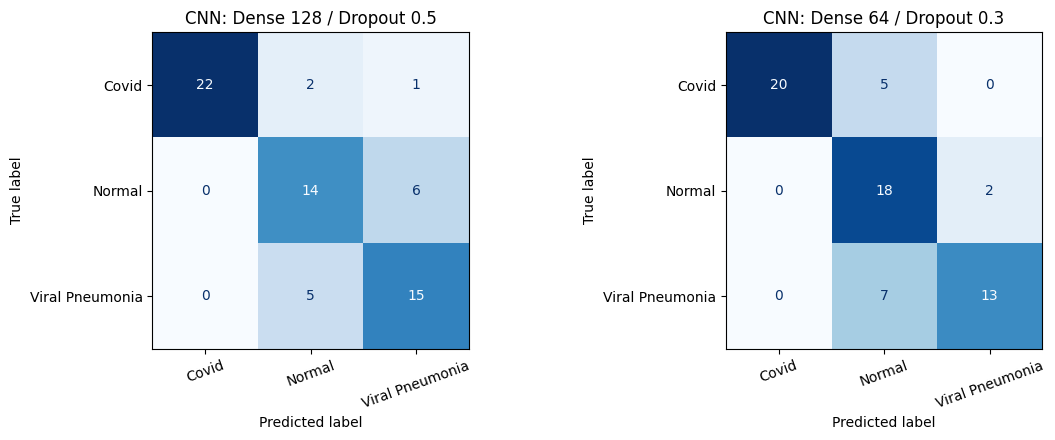

In [7]:
@torch.inference_mode()
def evaluate_cnn(model, loader):
    model.eval()
    probabilities, true_labels = [], []
    total_loss, sample_count = 0.0, 0
    criterion = nn.CrossEntropyLoss(reduction="sum")
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        logits = model(images)
        total_loss += criterion(logits, labels).item()
        sample_count += labels.size(0)
        probabilities.append(torch.softmax(logits, dim=1).cpu().numpy())
        true_labels.append(labels.cpu().numpy())
    probabilities = np.concatenate(probabilities)
    labels = np.concatenate(true_labels)
    predictions = probabilities.argmax(axis=1)
    np.testing.assert_allclose(probabilities.sum(axis=1), 1, atol=1e-6)
    return {"labels": labels, "predictions": predictions, "probabilities": probabilities,
            "test_loss": total_loss / sample_count,
            "accuracy": accuracy_score(labels, predictions),
            "weighted_f1": f1_score(labels, predictions, average="weighted", zero_division=0),
            "macro_f1": f1_score(labels, predictions, average="macro", zero_division=0)}


b_evaluations = {}
b_test_rows = []
b_test_loader = make_cnn_loader(b_test_dataset, B_EVAL_BATCH_SIZE)
b_prediction_table = b_test_manifest[["relative_path", "class_name", "label"]].copy()
for model_id, run in b_runs.items():
    restored_model = make_cnn(run["config"]).to(DEVICE)
    restored_model.load_state_dict(run["state_dict"])
    evaluation = evaluate_cnn(restored_model, b_test_loader)
    np.testing.assert_array_equal(evaluation["labels"], b_test_manifest["label"].to_numpy())
    b_evaluations[model_id] = evaluation
    b_test_rows.append({
        "model_id": model_id, "model": run["config"]["name"],
        "test_loss": evaluation["test_loss"], "test_accuracy": evaluation["accuracy"],
        "test_weighted_f1": evaluation["weighted_f1"], "test_macro_f1": evaluation["macro_f1"],
        "selected_by_validation": model_id == B_SELECTED_ID,
    })
    report_arguments = {"labels": list(range(len(B_CLASS_NAMES))), "target_names": B_CLASS_NAMES,
                        "zero_division": 0}
    print(f"\n{run['config']['name']} - held-out test")
    print(classification_report(evaluation["labels"], evaluation["predictions"], digits=4, **report_arguments))
    report = classification_report(evaluation["labels"], evaluation["predictions"],
                                   output_dict=True, **report_arguments)
    pd.DataFrame(report).transpose().to_csv(B_TABLE_DIR / f"{model_id}_classification_report.csv")
    b_prediction_table[f"{model_id}_prediction"] = [B_CLASS_NAMES[index] for index in evaluation["predictions"]]
    for index, class_name in enumerate(B_CLASS_NAMES):
        b_prediction_table[f"{model_id}_probability_{class_name}"] = evaluation["probabilities"][:, index]
    del restored_model
b_test_results = pd.DataFrame(b_test_rows).set_index("model_id")
b_cnn_results = b_training_summary.join(b_test_results.drop(columns="model"))
b_cnn_results.to_csv(B_TABLE_DIR / "cnn_comparison.csv")
b_prediction_table.to_csv(B_TABLE_DIR / "test_predictions.csv", index=False)
display(b_cnn_results.round(4))

fig, axes = plt.subplots(1, len(B_VARIANTS), figsize=(12, 4.5), squeeze=False)
for ax, variant in zip(axes[0], B_VARIANTS):
    evaluation = b_evaluations[variant["id"]]
    ConfusionMatrixDisplay(
        confusion_matrix(evaluation["labels"], evaluation["predictions"], labels=range(len(B_CLASS_NAMES))),
        display_labels=B_CLASS_NAMES,
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(variant["name"])
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(B_FIGURE_DIR / "confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()

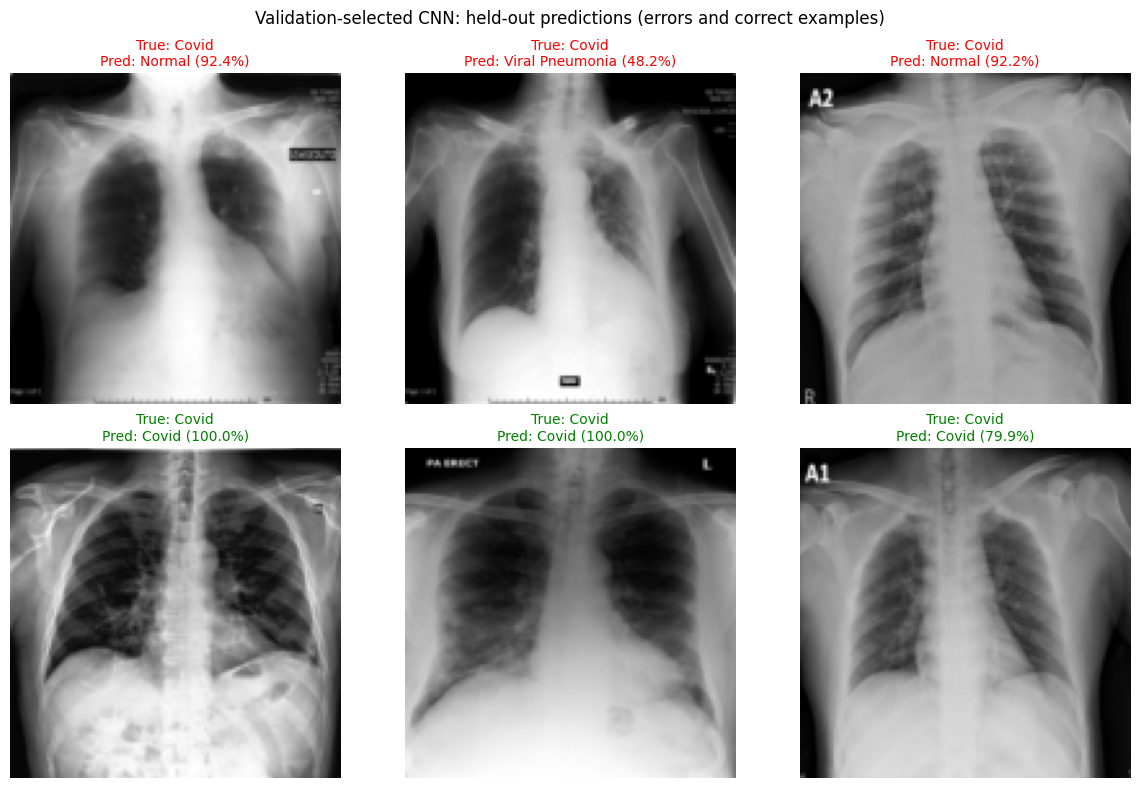

,model,model_type,fit_images,validation_images,test_images,test_accuracy,test_weighted_f1,test_macro_f1,test_loss,selection_protocol,selection_accuracy,selected_within_family
0,Random Forest,Traditional ML,242,0,65,0.8308,0.8292,0.8183,NaN,5-fold training CV,0.9172,False
1,"PyTorch MLP (128, 64)",Traditional ML,242,0,65,0.9077,0.9073,0.9062,NaN,5-fold training CV,0.9462,True
2,CNN: Dense 128 / Dropout 0.5,Deep Learning,193,49,65,0.7846,0.7900,0.7778,0.4893,Training validation holdout,0.9388,True
3,CNN: Dense 64 / Dropout 0.3,Deep Learning,193,49,65,0.7846,0.7920,0.7839,0.5066,Training validation holdout,0.9388,False


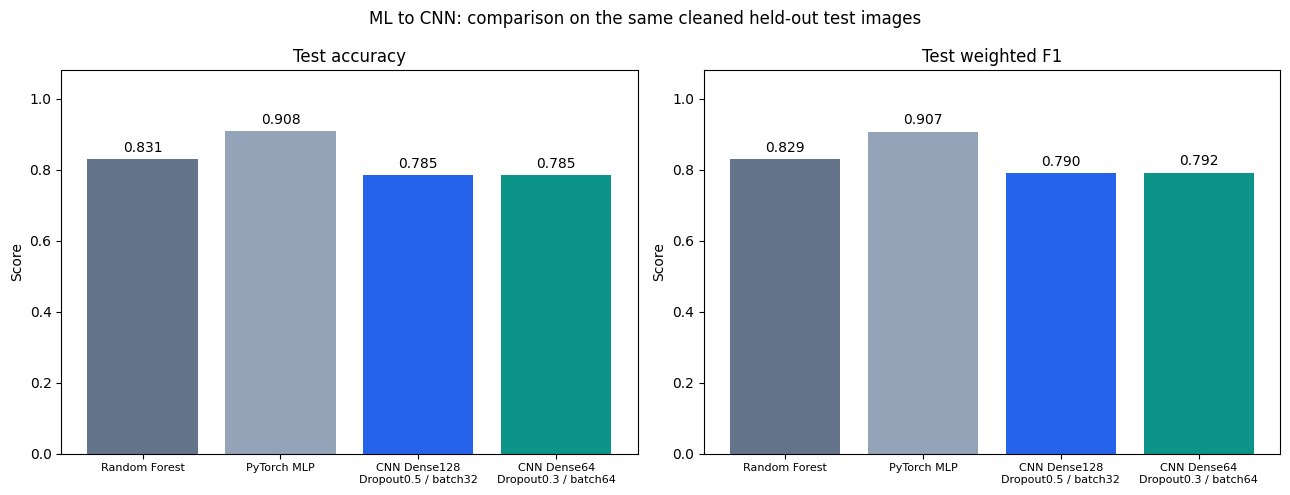

**Validation-selected CNN: CNN: Dense 128 / Dropout 0.5.** Restored epoch 12 of 12 executed epochs, with validation accuracy 0.939. Its held-out accuracy is 0.785, weighted F1 is 0.790, and cross-entropy loss is 0.489. The test accuracy difference from the CV-selected ML baseline (PyTorch MLP (128, 64)) is -12.31 percentage points. CNN selection remains based on validation.

Convolutions preserve local spatial relationships, while the ML baselines use flattened pixels. Differences may also reflect input resolution, fitting-set size, regularisation, batch size, and optimisation, and training augmentation; these experiments do not isolate architecture as the cause. Inspect the learning curves and per-class errors for overfitting. A single error changes test accuracy by about 1.54 percentage points, so small differences are uncertain. Exact deduplication does not establish patient independence or clinical generalisation.

In [8]:
b_selected_evaluation = b_evaluations[B_SELECTED_ID]
b_correct = np.flatnonzero(b_selected_evaluation["predictions"] == b_selected_evaluation["labels"])
b_incorrect = np.flatnonzero(b_selected_evaluation["predictions"] != b_selected_evaluation["labels"])
example_indices = list(b_incorrect[:3]) + list(b_correct[:3])
if len(example_indices) < 6:
    example_indices += [index for index in range(len(b_test_dataset)) if index not in example_indices][:6 - len(example_indices)]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, index in zip(axes.flat, example_indices):
    image, true_label = b_test_dataset[index]
    predicted_label = b_selected_evaluation["predictions"][index]
    confidence = b_selected_evaluation["probabilities"][index, predicted_label]
    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"True: {B_CLASS_NAMES[true_label]}\nPred: {B_CLASS_NAMES[predicted_label]} ({confidence:.1%})",
                 color="green" if true_label == predicted_label else "red", fontsize=10)
    ax.axis("off")
fig.suptitle("Validation-selected CNN: held-out predictions (errors and correct examples)")
fig.tight_layout()
fig.savefig(B_FIGURE_DIR / "test_prediction_examples.png", dpi=180, bbox_inches="tight")
plt.show()

b_part_a_results = pd.read_csv(part_a_dir / "tables" / "model_comparison.csv")
b_combined_rows = []
for _, row in b_part_a_results.iterrows():
    b_combined_rows.append({
        "model": row["model"], "model_type": "Traditional ML",
        "fit_images": len(b_original_train), "validation_images": 0, "test_images": len(b_test_dataset),
        "test_accuracy": row["test_accuracy"], "test_weighted_f1": row["test_weighted_f1"],
        "test_macro_f1": row["test_macro_f1"], "test_loss": np.nan,
        "selection_protocol": "5-fold training CV", "selection_accuracy": row["cv_accuracy_mean"],
        "selected_within_family": row["selected_by_cv"],
    })
for model_id, row in b_cnn_results.iterrows():
    b_combined_rows.append({
        "model": row["model"], "model_type": "Deep Learning",
        "fit_images": len(b_train_dataset), "validation_images": len(b_validation_dataset),
        "test_images": len(b_test_dataset),
        "test_accuracy": row["test_accuracy"], "test_weighted_f1": row["test_weighted_f1"],
        "test_macro_f1": row["test_macro_f1"], "test_loss": row["test_loss"],
        "selection_protocol": "Training validation holdout", "selection_accuracy": row["best_val_accuracy"],
        "selected_within_family": model_id == B_SELECTED_ID,
    })
b_combined_comparison = pd.DataFrame(b_combined_rows)
b_combined_comparison.to_csv(B_TABLE_DIR / "ml_cnn_comparison.csv", index=False)
display(b_combined_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_labels = ["Random Forest", "PyTorch MLP", "CNN Dense128\nDropout0.5 / batch32", "CNN Dense64\nDropout0.3 / batch64"]
for ax, metric, title in zip(axes, ("test_accuracy", "test_weighted_f1"), ("Test accuracy", "Test weighted F1")):
    bars = ax.bar(plot_labels, b_combined_comparison[metric], color=["#64748b", "#94a3b8", "#2563eb", "#0d9488"])
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set(title=title, ylabel="Score", ylim=(0, 1.08))
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("ML to CNN: comparison on the same cleaned held-out test images")
fig.tight_layout()
fig.savefig(B_FIGURE_DIR / "ml_cnn_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

selected_row = b_cnn_results.loc[B_SELECTED_ID]
best_ml_row = b_part_a_results.loc[b_part_a_results["selected_by_cv"]].iloc[0]
accuracy_difference = selected_row["test_accuracy"] - best_ml_row["test_accuracy"]
display(Markdown(
    f"**Validation-selected CNN: {selected_row['model']}.** Restored epoch "
    f"{int(selected_row['best_epoch'])} of {int(selected_row['epochs_run'])} executed epochs, "
    f"with validation accuracy {selected_row['best_val_accuracy']:.3f}. "
    f"Its held-out accuracy is {selected_row['test_accuracy']:.3f}, weighted F1 is "
    f"{selected_row['test_weighted_f1']:.3f}, and cross-entropy loss is {selected_row['test_loss']:.3f}. "
    f"The test accuracy difference from the CV-selected ML baseline ({best_ml_row['model']}) is "
    f"{100 * accuracy_difference:+.2f} percentage points. CNN selection remains based on validation."
))
display(Markdown(
    "Convolutions preserve local spatial relationships, while the ML baselines use flattened pixels. "
    "Differences may also reflect input resolution, fitting-set size, regularisation, batch size, and "
    "optimisation, and training augmentation; these experiments do not isolate architecture as the cause. Inspect the learning "
    "curves and per-class errors for overfitting. A single error changes test accuracy by about "
    f"{100 / len(b_test_dataset):.2f} percentage points, so small differences are uncertain. "
    "Exact deduplication does not establish patient independence or clinical generalisation."
))

### B.5 - Save trained models and training histories

Save each restored checkpoint in native PyTorch **`.pt`** format and as a genuine
**HDF5 `.h5`** file, together with architecture, image preprocessing, label mapping,
best epoch, and validation-selection metadata. The HDF5 files contain PyTorch weights
and JSON configuration; they are explicitly **not Keras models**. Use the provided
`load_cnn_h5` function to reconstruct them.

The validation-selected model is also copied to `best_cnn.pt` and `best_cnn.h5`.
Save every epoch's history and all evaluation tables/figures. Verify both formats
restore every parameter exactly, then check CPU inference equivalence on sample inputs.
No retraining or test-based parameter changes occur during export.

Training augmentation settings are saved as provenance; inference uses only the
deterministic preprocessing described in the checkpoint metadata.

In [9]:
def cnn_export_metadata(model_id, run):
    return {
        "format": "portfolio-pytorch-cnn-v1", "framework": "pytorch",
        "model_id": model_id, "name": run["config"]["name"],
        "architecture": {"num_classes": len(B_CLASS_NAMES), "dense_units": run["config"]["dense_units"],
                         "dropout": run["config"]["dropout"], "conv_channels": [32, 64, 128],
                         "kernel_size": 3, "padding": 0, "pool_size": 2},
        "preprocessing": {"image_size": list(B_IMAGE_SIZE), "channels": 1, "color_mode": "L",
                          "resize_interpolation": "bilinear", "pixel_divisor": 255.0,
                          "exif_transpose": True},
        "class_names": B_CLASS_NAMES, "class_to_index": B_CLASS_TO_INDEX,
        "training_augmentation": dict(B_AUGMENTATION_CONFIG),
        "max_epochs": B_MAX_EPOCHS,
        "early_stopping_patience": B_EARLY_STOPPING_PATIENCE,
        "best_epoch": run["best_epoch"], "epochs_run": run["epochs_run"],
        "best_val_accuracy": run["best_val_accuracy"], "best_val_loss": run["best_val_loss"],
        "selected_by_validation": model_id == B_SELECTED_ID,
        "test_manifest": "tables/image_split_manifest.csv",
    }


def save_cnn_h5(file_path, state_dict, metadata):
    with h5py.File(file_path, "w") as handle:
        handle.attrs["format"] = "portfolio-pytorch-cnn-v1"
        handle.attrs["metadata_json"] = json.dumps(metadata)
        weights = handle.create_group("state_dict")
        for name, tensor in state_dict.items():
            weights.create_dataset(name, data=tensor.detach().cpu().numpy(), compression="gzip")


def cnn_from_metadata(metadata):
    architecture = metadata["architecture"]
    return ImageCNN(
        architecture["num_classes"], architecture["dense_units"], architecture["dropout"],
        tuple(metadata["preprocessing"]["image_size"]),
    )


def load_cnn_h5(file_path, device="cpu"):
    with h5py.File(file_path, "r") as handle:
        if handle.attrs["format"] != "portfolio-pytorch-cnn-v1":
            raise ValueError("Unsupported CNN HDF5 checkpoint format.")
        metadata = json.loads(handle.attrs["metadata_json"])
        state_dict = {name: torch.from_numpy(dataset[...]) for name, dataset in handle["state_dict"].items()}
    model = cnn_from_metadata(metadata)
    model.load_state_dict(state_dict, strict=True)
    return model.to(device).eval(), metadata


b_reload_rows = []
reload_sample = torch.stack([b_test_dataset[index][0] for index in range(min(3, len(b_test_dataset)))])
for model_id, run in b_runs.items():
    metadata = cnn_export_metadata(model_id, run)
    pt_path = B_MODEL_DIR / f"{model_id}.pt"
    h5_path = B_MODEL_DIR / f"{model_id}.h5"
    torch.save({"state_dict": run["state_dict"], "metadata": metadata}, pt_path)
    save_cnn_h5(h5_path, run["state_dict"], metadata)
    (B_MODEL_DIR / f"{model_id}_config.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    pt_checkpoint = torch.load(pt_path, map_location="cpu", weights_only=True)
    pt_model = cnn_from_metadata(pt_checkpoint["metadata"])
    pt_model.load_state_dict(pt_checkpoint["state_dict"], strict=True)
    pt_model.eval()
    h5_model, h5_metadata = load_cnn_h5(h5_path)
    reference_model = make_cnn(run["config"]).eval()
    reference_model.load_state_dict(run["state_dict"])
    for name, tensor in run["state_dict"].items():
        assert torch.equal(pt_model.state_dict()[name], tensor)
        assert torch.equal(h5_model.state_dict()[name], tensor)
    assert h5_metadata == metadata == pt_checkpoint["metadata"]
    with torch.inference_mode():
        reference_logits = reference_model(reload_sample)
        pt_logits, h5_logits = pt_model(reload_sample), h5_model(reload_sample)
    torch.testing.assert_close(pt_logits, reference_logits, rtol=0, atol=0)
    torch.testing.assert_close(h5_logits, reference_logits, rtol=0, atol=0)
    b_reload_rows.append({"model_id": model_id, "pt_parameters_equal": True, "h5_parameters_equal": True,
                          "pt_max_logit_difference": (pt_logits - reference_logits).abs().max().item(),
                          "h5_max_logit_difference": (h5_logits - reference_logits).abs().max().item()})
    del pt_model, h5_model, reference_model

for extension in ("pt", "h5"):
    shutil.copyfile(B_MODEL_DIR / f"{B_SELECTED_ID}.{extension}", B_MODEL_DIR / f"best_cnn.{extension}")
b_reload_verification = pd.DataFrame(b_reload_rows)
b_reload_verification.to_csv(B_TABLE_DIR / "checkpoint_reload_verification.csv", index=False)
display(b_reload_verification)

b_experiment_config = {
    "seed": SEED, "image_size": list(B_IMAGE_SIZE), "input_channels": B_INPUT_CHANNELS,
    "class_to_index": B_CLASS_TO_INDEX, "max_epochs": B_MAX_EPOCHS,
    "early_stopping_monitor": "validation_accuracy", "early_stopping_patience": B_EARLY_STOPPING_PATIENCE,
    "lr_plateau_epochs": B_LR_PLATEAU_EPOCHS, "lr_scheduler_pytorch_patience": B_LR_PLATEAU_EPOCHS - 1,
    "lr_reduction_factor": 0.5, "optimizer": "Adam", "initial_learning_rate": B_LEARNING_RATE,
    "mixed_precision": B_USE_AMP, "num_workers": B_NUM_WORKERS, "pin_memory": DEVICE.type == "cuda",
    "variants": B_VARIANTS, "fit_images": len(b_train_dataset),
    "validation_images": len(b_validation_dataset), "test_images": len(b_test_dataset),
    "validation_fraction": B_VALIDATION_FRACTION,
    "selection_rule": "best validation accuracy, then lower validation loss",
    "selected_cnn": B_SELECTED_ID, "augmentation": dict(B_AUGMENTATION_CONFIG),
}
b_runtime = {**runtime_info, "torchvision_version": torchvision.__version__, "h5py_version": h5py.__version__,
             "cnn_device": str(DEVICE), "logical_cpu_count": os.cpu_count()}
(B_OUTPUT_DIR / "experiment_config.json").write_text(json.dumps(b_experiment_config, indent=2), encoding="utf-8")
(B_OUTPUT_DIR / "runtime.json").write_text(json.dumps(b_runtime, indent=2), encoding="utf-8")
print(f"Part B complete. Selected CNN: {B_SELECTED_ID}")
print(f"Saved tables and histories: {B_TABLE_DIR}")
print(f"Saved figures: {B_FIGURE_DIR}")
print(f"Saved .pt and .h5 checkpoints: {B_MODEL_DIR}")

,model_id,pt_parameters_equal,h5_parameters_equal,pt_max_logit_difference,h5_max_logit_difference
0,cnn_dense128_dropout05,True,True,0.0,0.0
1,cnn_dense64_dropout03,True,True,0.0,0.0


Part B complete. Selected CNN: cnn_dense128_dropout05
Saved tables and histories: D:\PortfolioTask3\artifacts\part_b\tables
Saved figures: D:\PortfolioTask3\artifacts\part_b\figures
Saved .pt and .h5 checkpoints: D:\PortfolioTask3\artifacts\part_b\models


<a id="method-references"></a>
## Method references

- [PyTorch CUDA availability](https://docs.pytorch.org/docs/stable/generated/torch.cuda.is_available.html)
- [PyTorch reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html)
- [scikit-learn: data leakage and preprocessing](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)
- [scikit-learn: RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)

The assignment PDF is available in `docs/`. The implemented code covers its unmarked
Part A and CNN Part B requirements. Part E is excluded.

- [PyTorch data loading and Windows multiprocessing](https://docs.pytorch.org/docs/2.11/data.html)
- [PyTorch automatic mixed precision](https://docs.pytorch.org/docs/2.11/amp.html)
- [PyTorch ReduceLROnPlateau](https://docs.pytorch.org/docs/2.11/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html)
- [Torchvision ImageFolder](https://docs.pytorch.org/vision/0.26/generated/torchvision.datasets.ImageFolder.html)
- [h5py: HDF5 datasets and metadata](https://docs.h5py.org/en/stable/quick.html)
- [Torchvision ColorJitter](https://docs.pytorch.org/vision/0.26/generated/torchvision.transforms.ColorJitter.html)
- [Torchvision RandomHorizontalFlip](https://docs.pytorch.org/vision/0.26/generated/torchvision.transforms.RandomHorizontalFlip.html)
- [Torchvision RandomRotation](https://docs.pytorch.org/vision/0.26/generated/torchvision.transforms.RandomRotation.html)